# Human Activity Recognition Using Machine Learning

## Member 3: Random Forest Classification and Feature Importance

**Dataset:** UCI Human Activity Recognition Using Smartphones

### Responsibilities
1. Understand the Random Forest classification algorithm.
2. Load the training and testing datasets.
3. Implement and train the Random Forest classifier.
4. Generate activity predictions.
5. Evaluate the model using accuracy, precision, recall, and F1-score.
6. Generate a confusion matrix.
7. Perform feature importance analysis.
8. Compare Random Forest performance with KNN and Decision Tree.
9. Identify the best-performing classification model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
DATASET_PATH = "../UCI HAR Dataset"

# Load training features and labels
X_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "X_train.txt"),
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "y_train.txt"),
    header=None
).values.ravel()

# Load testing features and labels
X_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "X_test.txt"),
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "y_test.txt"),
    header=None
).values.ravel()

print("Dataset loaded successfully!")
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training features: (7352, 561)
Training labels: (7352,)
Testing features: (2947, 561)
Testing labels: (2947,)


In [3]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nUnique activity labels:")
print(np.unique(y_train))

print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Training data shape: (7352, 561)
Testing data shape: (2947, 561)

Unique activity labels:
[1 2 3 4 5 6]

Missing values in training data: 0
Missing values in testing data: 0



## Random Forest Classification

Random Forest is a supervised machine learning algorithm used for classification and regression tasks.

It creates multiple Decision Trees and combines their predictions to produce a final result. For classification, the final prediction is generally determined by majority voting among the trees.

### How Random Forest Works
1. Selects random samples from the training dataset.
2. Builds multiple Decision Trees.
3. Each tree makes its own prediction.
4. Combines the predictions using majority voting.
5. Produces the final predicted activity.

### Advantages
- Reduces overfitting compared with a single Decision Tree in many cases.
- Handles datasets with many features.
- Provides feature importance scores.
- Often produces good classification performance.




In [3]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [4]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")

print("\nFirst 20 Actual Labels:")
print(y_test[:20])

print("\nFirst 20 Predicted Labels:")
print(y_pred_rf[:20])

Random Forest predictions generated successfully!

First 20 Actual Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]

First 20 Predicted Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]


In [5]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average="weighted")
rf_recall = recall_score(y_test, y_pred_rf, average="weighted")
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")

print("Random Forest Model Performance")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-score :", round(rf_f1, 4))

Random Forest Model Performance
--------------------------------
Accuracy : 0.9257
Precision: 0.927
Recall   : 0.9257
F1-score : 0.9255


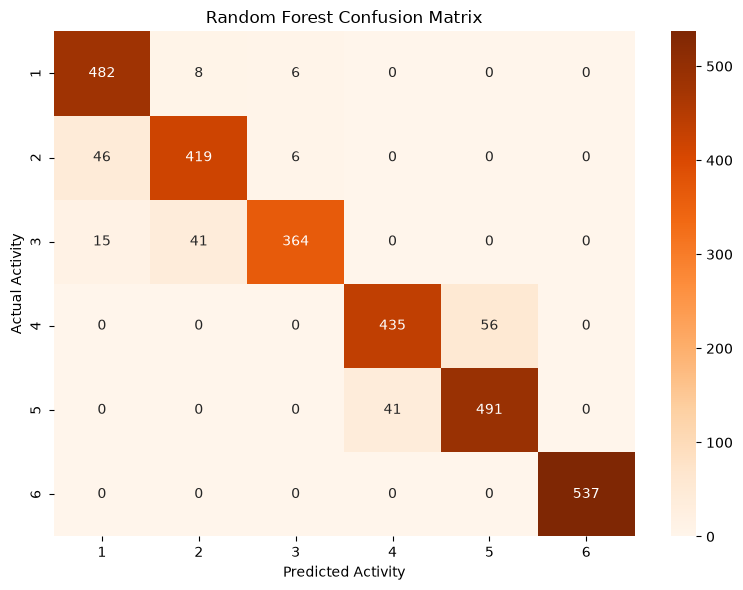

In [6]:
rf_cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

In [7]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Most Important Features:")
display(feature_importance.head(10))

Top 10 Most Important Features:


,Feature,Importance
40,40,0.036380
49,49,0.030331
558,558,0.029676
41,41,0.025355
56,56,0.024963
559,559,0.024415
52,52,0.022650
50,50,0.021705
53,53,0.021635
57,57,0.017179


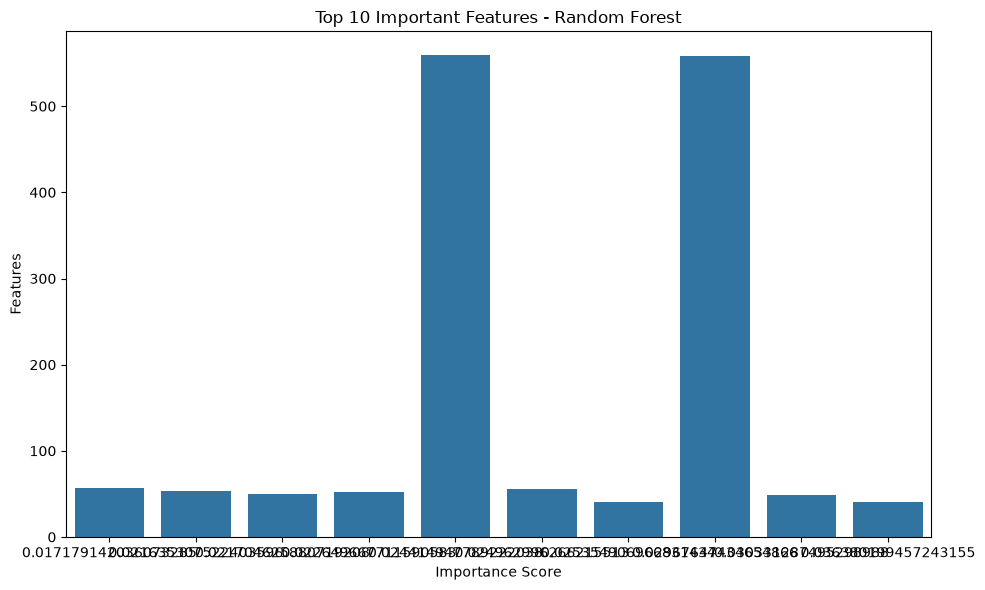

In [8]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [9]:
model_comparison = pd.DataFrame({
    "Model": ["KNN", "Decision Tree", "Random Forest"],

    "Accuracy": [
        0.8802,
        0.8622,
        rf_accuracy
    ],

    "Precision": [
        0.8883,
        0.8633,
        rf_precision
    ],

    "Recall": [
        0.8802,
        0.8622,
        rf_recall
    ],

    "F1-Score": [
        0.8790,
        0.8617,
        rf_f1
    ]
})

print("Classification Model Performance Comparison:")
display(model_comparison.round(4))

Classification Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.8802,0.8883,0.8802,0.8790
1,Decision Tree,0.8622,0.8633,0.8622,0.8617
2,Random Forest,0.9257,0.9270,0.9257,0.9255


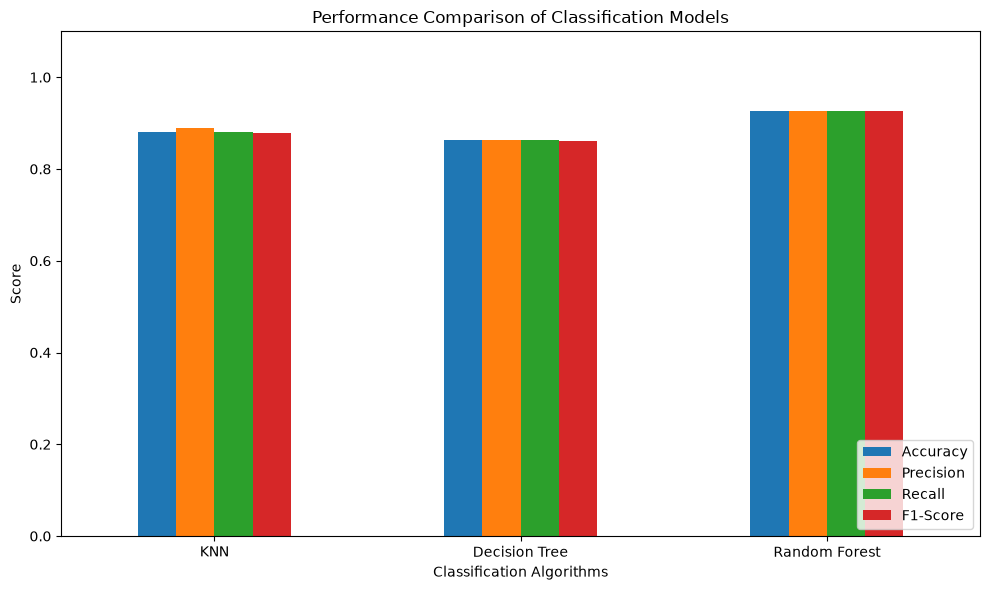

In [10]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

model_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Algorithms")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Part 2: Data Preprocessing

Data preprocessing is an important step in machine learning. It prepares the dataset for effective model development.

In this section, we perform the following operations:

1. Verify missing values and duplicate records.
2. Separate input features (X) and target labels (y).
3. Apply feature scaling using StandardScaler.
4. Prepare and save the processed dataset for further machine learning tasks.

These operations help maintain data quality and ensure consistency in the machine learning workflow.

In [11]:
# Check for missing values
print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

# Check for duplicate records
print("Duplicate records in training data:", X_train.duplicated().sum())
print("Duplicate records in testing data:", X_test.duplicated().sum())

Missing values in training data: 0
Missing values in testing data: 0
Duplicate records in training data: 0
Duplicate records in testing data: 0


In [12]:
# Separate features and target labels

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

y_train_processed = y_train.copy()
y_test_processed = y_test.copy()

print("Training features shape:", X_train_processed.shape)
print("Testing features shape:", X_test_processed.shape)

print("Training target shape:", y_train_processed.shape)
print("Testing target shape:", y_test_processed.shape)

Training features shape: (7352, 561)
Testing features shape: (2947, 561)
Training target shape: (7352,)
Testing target shape: (2947,)


In [13]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both datasets
X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

print("Training data after scaling:", X_train_scaled.shape)
print("Testing data after scaling:", X_test_scaled.shape)

print("\nMean of first scaled feature:", X_train_scaled[:, 0].mean())
print("Standard deviation of first scaled feature:", X_train_scaled[:, 0].std())

Training data after scaling: (7352, 561)
Testing data after scaling: (2947, 561)

Mean of first scaled feature: -3.131336321902509e-16
Standard deviation of first scaled feature: 0.9999999999999999


### 5. Saving the Processed Dataset

After performing feature scaling, the processed training and testing datasets are saved as CSV files.

The target activity labels are also saved separately.



In [15]:
import os
import pandas as pd

# Create output folder
os.makedirs("Member3_Output", exist_ok=True)

# Save scaled feature datasets
pd.DataFrame(X_train_scaled).to_csv(
    "Member3_Output/X_train_scaled.csv", index=False
)

pd.DataFrame(X_test_scaled).to_csv(
    "Member3_Output/X_test_scaled.csv", index=False
)

# Save target labels
pd.DataFrame(y_train_processed).to_csv(
    "Member3_Output/y_train.csv", index=False
)

pd.DataFrame(y_test_processed).to_csv(
    "Member3_Output/y_test.csv", index=False
)

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


### 6. Saving the StandardScaler

The fitted StandardScaler is saved using Joblib. This allows other team members to reuse the same scaling parameters without fitting a new scaler.

In [16]:
import joblib

# Save the fitted scaler
joblib.dump(scaler, "Member3_Output/scaler.pkl")

print("StandardScaler saved successfully!")

StandardScaler saved successfully!


## 7. Preprocessing Observations

1. The dataset was checked for missing values and duplicate records.
2. The training dataset contains 7,352 observations and 561 features.
3. The testing dataset contains 2,947 observations and 561 features.
4. Input features (X) and target activity labels (y) were separated.
5. StandardScaler was used to standardize the features.
6. The scaler was fitted on the training data and applied to the testing data to prevent data leakage.
7. The processed datasets and fitted scaler were saved successfully for future use.

## 8. Conclusion

The data preprocessing stage was completed successfully. The dataset was inspected, features and target labels were separated, and feature scaling was performed using StandardScaler.

The processed datasets and scaler were saved for reuse in the next stage of the project, particularly K-Means clustering.